# 02 · Rainfall from CHIRPS

**Project:** Spatio-Temporal Prediction of Pluvial and Coastal Flood Risk in Lagos State, Nigeria
**Notebook:** 02 of the series · **Author:** Utibe Bassey

## Purpose

Rainfall is the main trigger of pluvial (rain-driven) flooding. This notebook gets the **daily rainfall for each Lagos LGA from 2010 to 2025** and turns it into monthly flood-relevant features.

## About the data

**CHIRPS** is a satellite-based rainfall dataset (Climate Hazards Group, UC Santa Barbara) that blends satellite imagery with rain-gauge records.

| Property | Value |
| --- | --- |
| Unit | millimetres of rain per day (mm/day) |
| Resolution | about 5.5 km per pixel (0.05 degrees) |
| Access | Google Earth Engine, collection `UCSB-CHG/CHIRPS/DAILY` |

## What this notebook does

1. Connects to Google Earth Engine
2. Loads the Lagos LGA map from notebook 01
3. Extracts the **daily mean rainfall per LGA**, in 6-month chunks, and saves each chunk
4. Checks the data for gaps and impossible values
5. Builds **monthly features**: total rain, heaviest day, heaviest 3-day and 7-day totals, rainy days and heavy-rain days
6. Saves `data/clean/rainfall_lga_month.csv` and draws two sanity-check charts

## Inputs and outputs

| | File | Notes |
| --- | --- | --- |
| **Input** | `data/clean/lagos_lgas.gpkg` | From notebook 01 |
| **Output** | `data/raw/chirps_daily_lga.csv` | Daily rainfall per LGA (about 117,000 rows) |
| **Output** | `data/clean/rainfall_lga_month.csv` | Monthly features, one row per LGA per month (3,840 rows) |

## 1. Setup

In [2]:
from pathlib import Path
import json
import time

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import ee   # Google Earth Engine library
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

### Settings

Everything you might want to change is in this one cell.

In [3]:
PROJECT_ID = "lagos-flood-risk"      # your Google Cloud project ID

START = "2010-01-01"                  # first day (inclusive)
END = "2026-01-01"                    # day AFTER the last day we want (end is exclusive)

CHUNK_MONTHS = 6                      # months per download chunk (smaller = safer, but slower)
SCALE_M = 5566                        # CHIRPS pixel size in metres (0.05 degrees)

LGA_PATH = Path("../data/clean/lagos_lgas.gpkg")
CHUNK_DIR = Path("../data/raw/chirps_chunks")           # one small file per chunk, so a failure never loses progress
DAILY_PATH = Path("../data/raw/chirps_daily_lga.csv")   # all daily data combined
MONTHLY_PATH = Path("../data/clean/rainfall_lga_month.csv")

CHUNK_DIR.mkdir(parents=True, exist_ok=True)
MONTHLY_PATH.parent.mkdir(parents=True, exist_ok=True)

## 2. Connect to Google Earth Engine

The first time, a browser window opens: tick **read-only scopes**, generate the token and paste it back here. After that the login is remembered.

> **If this fails with "Earth Engine API has not been used in project..."**, enable the API at `console.developers.google.com/apis/api/earthengine.googleapis.com/overview?project=lagos-flood-risk`, wait 2-5 minutes, then rerun this cell. Also check that the project is registered for Earth Engine at `code.earthengine.google.com/register`.

In [6]:
try:
    ee.Initialize(project=PROJECT_ID)       # works if you have logged in before
except Exception:
    ee.Authenticate()                       # opens the browser login
    ee.Initialize(project=PROJECT_ID)

print("Connected to Earth Engine")

Connected to Earth Engine


## 3. Load the LGA map and the CHIRPS collection

Earth Engine needs the LGA shapes in its own format. We simplify the outlines slightly (to about 100 m) so the request stays small. This does not matter for rainfall, because one CHIRPS pixel is 5.5 km wide.

In [7]:
lagos = gpd.read_file(LGA_PATH)
print("LGAs loaded:", len(lagos))

# Simplify outlines a little (0.001 degrees is about 100 m) to keep the upload small
lagos_simple = lagos.copy()
lagos_simple["geometry"] = lagos_simple.geometry.simplify(0.001, preserve_topology=True)

# Convert to an Earth Engine FeatureCollection (each feature keeps its 'lga' name)
lagos_fc = ee.FeatureCollection(json.loads(lagos_simple.to_json())["features"])
print("Features sent to Earth Engine:", lagos_fc.size().getInfo())

LGAs loaded: 20
Features sent to Earth Engine: 20


In [8]:
chirps = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY").select("precipitation")

# Confirm the data covers our period
newest = chirps.sort("system:time_start", False).first().date().format("YYYY-MM-dd").getInfo()
print("Newest CHIRPS day available:", newest)   # should be later than 2025-12-31

Newest CHIRPS day available: 2026-09-30


## 4. Extract daily rainfall per LGA

**How it works:** for every day, Earth Engine averages the rain over all pixels inside each LGA. That gives 20 numbers per day, one for each LGA.

**Important limit:** a CHIRPS pixel is about 5.5 km wide, and many central Lagos LGAs (Lagos Island, Apapa, Mushin, Shomolu and others) are smaller than that. Their rainfall values will be **very similar to their neighbours'**. Rainfall will separate the coast, the north and the east from each other, but it cannot separate neighbouring small LGAs. Elevation, land cover and drainage will do that job. This goes in the limitations section of the report.

The extraction runs in 6-month chunks. Each finished chunk is saved to `data/raw/chirps_chunks/`, so if the connection drops you can rerun the cell and it **skips the chunks already done**.

In [9]:
def extract_chunk(start, end):
    """Daily mean rainfall for every LGA between start (inclusive) and end (exclusive)."""
    images = chirps.filterDate(start, end)

    def per_day(img):
        day = img.date().format("YYYY-MM-dd")
        # average the pixels inside each LGA polygon
        stats = img.reduceRegions(collection=lagos_fc, reducer=ee.Reducer.mean(), scale=SCALE_M)
        return stats.map(lambda f: f.set("date", day))

    table = images.map(per_day).flatten()
    table = table.select(["lga", "date", "mean"], None, False)   # keep 3 columns, drop the shapes
    rows = table.getInfo()["features"]
    return pd.DataFrame([r["properties"] for r in rows])

In [10]:
# Build the list of chunks: [start, end) pairs, CHUNK_MONTHS apart
edges = pd.date_range(START, END, freq=f"{CHUNK_MONTHS}MS")
if edges[-1] != pd.Timestamp(END):
    edges = edges.append(pd.DatetimeIndex([END]))
chunks = list(zip(edges[:-1], edges[1:]))
print(f"{len(chunks)} chunks to process")

for i, (s, e) in enumerate(chunks, start=1):
    s_txt, e_txt = s.strftime("%Y-%m-%d"), e.strftime("%Y-%m-%d")
    out = CHUNK_DIR / f"chirps_{s_txt}_{e_txt}.csv"

    if out.exists():                                   # already downloaded, skip it
        print(f"[{i}/{len(chunks)}] {s_txt} to {e_txt}: already done")
        continue

    for attempt in range(1, 4):                        # up to 3 tries per chunk
        try:
            df_chunk = extract_chunk(s_txt, e_txt)
            df_chunk.to_csv(out, index=False)
            print(f"[{i}/{len(chunks)}] {s_txt} to {e_txt}: {len(df_chunk)} rows")
            break
        except Exception as err:
            print(f"[{i}/{len(chunks)}] attempt {attempt} failed: {str(err)[:120]}")
            time.sleep(10)
    else:
        print(f"Chunk {s_txt} to {e_txt} failed 3 times. Rerun this cell to try it again.")

32 chunks to process
[1/32] 2010-01-01 to 2010-07-01: 3620 rows
[2/32] 2010-07-01 to 2011-01-01: 3680 rows
[3/32] 2011-01-01 to 2011-07-01: 3620 rows
[4/32] 2011-07-01 to 2012-01-01: 3680 rows
[5/32] 2012-01-01 to 2012-07-01: 3640 rows
[6/32] 2012-07-01 to 2013-01-01: 3680 rows
[7/32] 2013-01-01 to 2013-07-01: 3620 rows
[8/32] 2013-07-01 to 2014-01-01: 3680 rows
[9/32] 2014-01-01 to 2014-07-01: 3620 rows
[10/32] 2014-07-01 to 2015-01-01: 3680 rows
[11/32] 2015-01-01 to 2015-07-01: 3620 rows
[12/32] 2015-07-01 to 2016-01-01: 3680 rows
[13/32] 2016-01-01 to 2016-07-01: 3640 rows
[14/32] 2016-07-01 to 2017-01-01: 3680 rows
[15/32] 2017-01-01 to 2017-07-01: 3620 rows
[16/32] 2017-07-01 to 2018-01-01: 3680 rows
[17/32] 2018-01-01 to 2018-07-01: 3620 rows
[18/32] 2018-07-01 to 2019-01-01: 3680 rows
[19/32] 2019-01-01 to 2019-07-01: 3620 rows
[20/32] 2019-07-01 to 2020-01-01: 3680 rows
[21/32] 2020-01-01 to 2020-07-01: 3640 rows
[22/32] 2020-07-01 to 2021-01-01: 3680 rows
[23/32] 2021-01-01 t

### Combine the chunks into one daily file

In [11]:
files = sorted(CHUNK_DIR.glob("chirps_*.csv"))
print("Chunk files found:", len(files), "of", len(chunks))

daily = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
daily = daily.rename(columns={"mean": "rain_mm"})
daily["date"] = pd.to_datetime(daily["date"])
daily = daily.sort_values(["lga", "date"]).reset_index(drop=True)

daily.to_csv(DAILY_PATH, index=False)
print("Saved:", DAILY_PATH.resolve())
daily.head()

Chunk files found: 32 of 32
Saved: C:\Users\LENOVO\Desktop\Portfolio Projects\lagos-flood-risk-ml\data\raw\chirps_daily_lga.csv


,date,lga,rain_mm
0,2010-01-01,Agege,0.0
1,2010-01-02,Agege,0.0
2,2010-01-03,Agege,0.0
3,2010-01-04,Agege,0.0
4,2010-01-05,Agege,0.0


## 5. Quality checks

Before using any data, confirm it is complete and sensible. **If a check fails, stop and fix it here**, because every later step depends on this data.

In [12]:
n_days = (pd.Timestamp(END) - pd.Timestamp(START)).days   # 5,844 days for 2010-2025
expected_rows = n_days * lagos["lga"].nunique()

print("Rows:", len(daily), "| expected:", expected_rows)
print("LGAs:", daily["lga"].nunique(), "| expected: 20")
print("Date range:", daily["date"].min().date(), "to", daily["date"].max().date())
print("Missing rain values:", daily["rain_mm"].isna().sum())
print("Negative values:", (daily["rain_mm"] < 0).sum())
print("Duplicate LGA-date rows:", daily.duplicated(["lga", "date"]).sum())
print("Largest daily value (mm):", round(daily["rain_mm"].max(), 1))

assert len(daily) == expected_rows, "Some days or LGAs are missing: rerun the extraction cell"
assert daily["rain_mm"].isna().sum() == 0
assert (daily["rain_mm"] >= 0).all()
assert not daily.duplicated(["lga", "date"]).any()
print("All checks passed")

Rows: 116880 | expected: 116880
LGAs: 20 | expected: 20
Date range: 2010-01-01 to 2025-12-31
Missing rain values: 0
Negative values: 0
Duplicate LGA-date rows: 0
Largest daily value (mm): 102.9
All checks passed


## 6. Build monthly features

The flood model works with one row per LGA per month. From the daily data we build features that capture **how much** and **how intense** the rain was:

| Feature | Meaning | Why it matters |
| --- | --- | --- |
| `rain_total_mm` | Total rain in the month | Wet ground and full drains |
| `rain_max_daily_mm` | Heaviest single day | Sudden downpours overwhelm drains |
| `rain_max_3day_mm` | Heaviest 3-day total | Several wet days in a row |
| `rain_max_7day_mm` | Heaviest 7-day total | Saturated soil and rising water levels |
| `rainy_days` | Days with at least 1 mm | How persistent the rain was |
| `heavy_rain_days` | Days with at least 20 mm | Count of intense rain events |

The 3-day and 7-day totals are calculated on the daily series first, so a wet spell that crosses a month boundary is counted correctly.

In [13]:
RAINY_DAY_MM = 1      # a day counts as rainy at or above this
HEAVY_DAY_MM = 20     # a day counts as heavy rain at or above this

# Rolling totals within each LGA (a NaN appears for the first few days of 2010, which is expected)
by_lga = daily.groupby("lga")["rain_mm"]
daily["rain_3day_mm"] = by_lga.transform(lambda s: s.rolling(3, min_periods=3).sum())
daily["rain_7day_mm"] = by_lga.transform(lambda s: s.rolling(7, min_periods=7).sum())

daily["rainy_day"] = daily["rain_mm"] >= RAINY_DAY_MM
daily["heavy_day"] = daily["rain_mm"] >= HEAVY_DAY_MM
daily["month"] = daily["date"].dt.to_period("M").dt.to_timestamp()   # first day of the month

monthly = (
    daily.groupby(["lga", "month"])
    .agg(
        rain_total_mm=("rain_mm", "sum"),
        rain_max_daily_mm=("rain_mm", "max"),
        rain_max_3day_mm=("rain_3day_mm", "max"),
        rain_max_7day_mm=("rain_7day_mm", "max"),
        rainy_days=("rainy_day", "sum"),
        heavy_rain_days=("heavy_day", "sum"),
    )
    .reset_index()
)

monthly["year"] = monthly["month"].dt.year
monthly["month_num"] = monthly["month"].dt.month
rain_cols = ["rain_total_mm", "rain_max_daily_mm", "rain_max_3day_mm", "rain_max_7day_mm"]
monthly[rain_cols] = monthly[rain_cols].round(1)   # one decimal place is plenty

print("Rows:", len(monthly), "| expected:", 20 * 12 * 16)
monthly.head()

Rows: 3840 | expected: 3840


,lga,month,rain_total_mm,rain_max_daily_mm,rain_max_3day_mm,rain_max_7day_mm,rainy_days,heavy_rain_days,year,month_num
0,Agege,2010-01-01,19.1,11.6,11.6,13.6,3,0,2010,1
1,Agege,2010-02-01,15.5,7.4,9.9,10.5,5,0,2010,2
2,Agege,2010-03-01,87.1,13.8,26.4,41.2,13,0,2010,3
3,Agege,2010-04-01,60.4,15.8,25.6,28.5,9,0,2010,4
4,Agege,2010-05-01,148.9,30.0,34.7,56.9,14,2,2010,5


In [14]:
# Save the monthly features for the modelling notebooks
monthly.to_csv(MONTHLY_PATH, index=False)
print("Saved:", MONTHLY_PATH.resolve())

monthly.describe().round(1)

Saved: C:\Users\LENOVO\Desktop\Portfolio Projects\lagos-flood-risk-ml\data\clean\rainfall_lga_month.csv


,month,rain_total_mm,rain_max_daily_mm,rain_max_3day_mm,rain_max_7day_mm,rainy_days,heavy_rain_days,year,month_num
count,3840,3840.0,3840.0,3840.0,3840.0,3840.0,3840.0,3840.0,3840.0
mean,2017-12-15 23:00:00,133.7,27.1,42.7,67.5,10.7,2.0,2017.5,6.5
min,2010-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,2010.0,1.0
25%,2013-12-24 06:00:00,44.8,12.4,19.6,31.5,6.0,0.0,2013.8,3.8
50%,2017-12-16 12:00:00,106.6,23.4,37.5,59.9,11.0,1.0,2017.5,6.5
75%,2021-12-08 18:00:00,204.0,39.4,61.0,94.3,15.0,3.0,2021.2,9.2
max,2025-12-01 00:00:00,559.9,102.9,183.2,236.7,26.0,15.0,2025.0,12.0
std,NaN,107.9,18.2,29.6,47.4,5.9,2.5,4.6,3.5


## 7. Sanity-check charts

Two charts to confirm the numbers behave like Lagos.

**Chart 1: the rainy season.** Lagos should show a main peak around May to July, a dip in August (the "little dry season"), a second smaller peak around September to October, and a dry season from December to February.

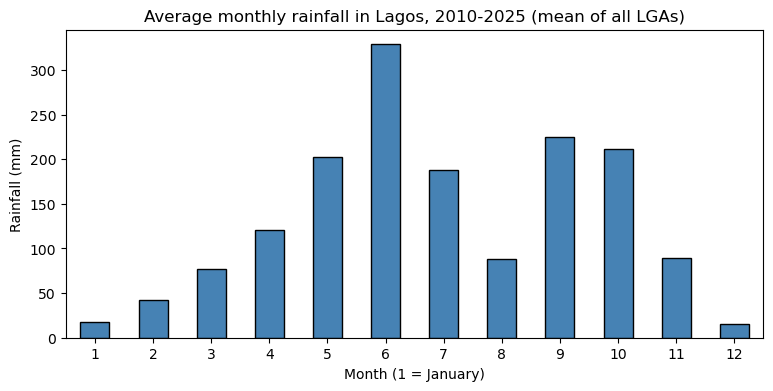

In [15]:
seasonal = monthly.groupby("month_num")["rain_total_mm"].mean()

ax = seasonal.plot.bar(figsize=(9, 4), color="steelblue", edgecolor="black")
ax.set_title("Average monthly rainfall in Lagos, 2010-2025 (mean of all LGAs)")
ax.set_xlabel("Month (1 = January)")
ax.set_ylabel("Rainfall (mm)")
plt.xticks(rotation=0)
plt.show()

**Chart 2: rainfall by LGA.** The west, the coast and the east differ a little, but many central LGAs look alike because of the 5.5 km pixel size, as explained in section 4. The annual total for Lagos is typically around 1,500 to 2,000 mm.

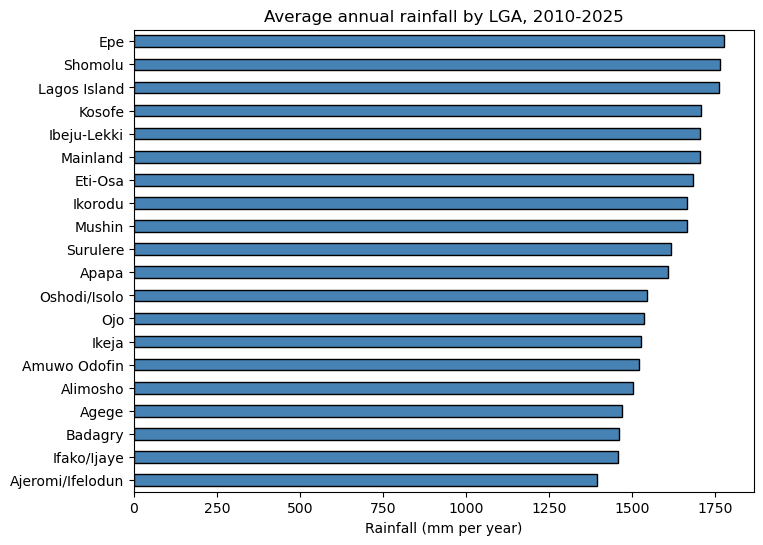

Range across LGAs (mm/year): 1394 to 1779


In [16]:
annual = (
    monthly.groupby(["lga", "year"])["rain_total_mm"].sum()
    .groupby("lga").mean()                # average yearly total for each LGA
    .sort_values()
)

ax = annual.plot.barh(figsize=(8, 6), color="steelblue", edgecolor="black")
ax.set_title("Average annual rainfall by LGA, 2010-2025")
ax.set_xlabel("Rainfall (mm per year)")
ax.set_ylabel("")
plt.show()

print("Range across LGAs (mm/year):", round(annual.min()), "to", round(annual.max()))

## Summary

- Extracted **daily CHIRPS rainfall** for all 20 LGAs, 2010-2025, and saved it to `data/raw/chirps_daily_lga.csv`
- Passed completeness checks on rows, gaps, negatives and duplicates
- Built **six monthly rainfall features** and saved them to `data/clean/rainfall_lga_month.csv`
- Confirmed that the seasonal pattern looks like Lagos

### Limitations to note in the report

- CHIRPS is a satellite estimate, not a gauge measurement, so it can differ from rain actually recorded on the ground
- The 5.5 km pixels cannot separate small neighbouring LGAs, so rainfall alone will not explain differences between them

### Next

**`03_elevation_and_water.ipynb`**: terrain height from SRTM, low-lying land and distance to the lagoon, rivers and coast for each LGA.